## Projet Data Science en nutrition humaine 

Les étapes d’un tel projet sont les suivantes : 
1. Formuler le problème scientifique dans un langage clair et facilement compréhensible. 
Donner des exemples de questions auxquelles ce projet peut répondre. 
2. Identifier les données disponibles. 
a. Évaluer leur volumétrie et leur qualité.  
b. Établir pour chaque jeu de données une fiche d’identification.  
c. Choisir les jeux de données qui seront utilisés pour le projet. 
3. Data engineering :  
a. Charger,  nettoyer,  explorer  et  visualiser  les  données  ;  les  organiser  dans  un 
modèle relationnel 
b. Gestion des valeurs manquantes 
c. Représentativité de l’échantillon et pondérations d’enquête 
d. Confidentialité (RGPD, données pseudonymisées) 
e. Biais de sélection et de déclaration (par exemple sous-déclaration des apports) 
4. Proposer  des  indicateurs  ainsi  que  les  méthodes  statistiques  ou  d’apprentissage 
automatique (ML) permettant de répondre aux questions identifiées à la première étape.  
5. Présenter les résultats et leur interprétation. 
6. Donner des arguments pour justifier 
a. Le choix des métriques 
b. La validation des méthodes choisies et la robustesse des résultats 
c. La reproductibilité du pipeline 
d. La traçabilité des données

### 1. Objectif :
**« Comment se caractérisent les consommations alimentaires et les apports 
nutritionnels de la population française, comment varient-ils selon l’âge et le sexe, et quels 
aliments y contribuent le plus ? »**  

Cette analyse permettra de répondre, par exemple, aux questions suivantes : 
- Quels sont les apports énergétiques moyens ?  
- Comment varient-ils selon l'âge et le sexe ?  
- Quels aliments contribuent le plus aux apports en protéines, calcium, fer, fibres, etc. ?  
- Quelle est la variabilité interindividuelle ?  
- Existe-t-il différents profils alimentaires ?  
- Comment comparer plusieurs enquêtes alimentaires ?  

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


On a 4013 individus commun à toutes les tables, on va donc traiter les données uniquemens sur les lignes en commun (ca devrait enlever des cas compliqués sur des na ...)

In [23]:
d_descri = pd.read_csv("tables/description-indiv.csv", sep=";", low_memory=False) #, low_memory=False uniquement pour supprimer le warning sur les colonnes de type object (colonnes qu'on supprime après de tte manière)
d_gpe = pd.read_csv("tables/conso-gpe-inca3.csv", sep=";")
d_app = pd.read_csv("tables/apports-nut-alim.csv", sep=";")
d_hab = pd.read_csv("tables/habitudes-indiv.csv", sep=";", low_memory=False)

noind_communs = set(d_gpe['NOIND']) & set(d_app['NOIND']) & set(d_hab['NOIND']) & set(d_descri['NOIND'])
df = d_descri[d_descri['NOIND'].isin(noind_communs)]

print(f"Nombre d'individus dans description-indiv.csv : {len(d_descri)}")
print(f"Nombre d'individus dans conso-gpe-inca3.csv : {len(d_gpe)}")
print(f"Nombre d'individus dans apports-nut-alim.csv : {len(d_app)}")
print(f"Nombre d'individus dans habitudes-indiv.csv : {len(d_hab)}")
print(f"Nombre d'individus communs : {len(noind_communs)}")

Nombre d'individus dans description-indiv.csv : 5855
Nombre d'individus dans conso-gpe-inca3.csv : 4114
Nombre d'individus dans apports-nut-alim.csv : 4114
Nombre d'individus dans habitudes-indiv.csv : 4372
Nombre d'individus communs : 4013


In [8]:
nb_str = len(df.select_dtypes(include=['object', 'string']).columns)
nb_num = len(df.select_dtypes(include=['number']).columns)

print("--- Décompte des types de colonnes ---")
print(f"Nombre de colonnes au format texte (str) : {nb_str}")
print(f"Nombre de colonnes au format numérique (int/float) : {nb_num}")
print('\n')

d_str = df.select_dtypes(include=['object', 'string'])
for k in d_str.columns:
    print(f"Colonne '{k}' : {d_str[k].nunique()} valeurs uniques, {d_str[k].isna().sum()} valeurs manquantes")
    print(d_str[k].unique())

df["zae"] = df["zae"].str[1:].astype("Int64") # Z78267 -> 78267
colonnes_libelle = df.columns[df.columns.str.endswith("_libelle")]
df.drop(columns=colonnes_libelle, inplace=True) # supprimer les colonnes *_libelles, les raisons du oui à la colonne d'avant, annecdotique pour nous

--- Décompte des types de colonnes ---
Nombre de colonnes au format texte (str) : 8
Nombre de colonnes au format numérique (int/float) : 177


Colonne 'zae' : 181 valeurs uniques, 0 valeurs manquantes
<StringArray>
['Z01091', 'Z03082', 'Z06030', 'Z06083', 'Z06155', 'Z06088', 'Z07204',
 'Z07324', 'Z12109', 'Z12133',
 ...
 'Z34172', 'Z57463', 'Z64102', 'Z69266', 'Z71486', 'Z86194', 'Z41059',
 'Z68375', 'Z83116', 'Z68224']
Length: 181, dtype: str
Colonne 'regime_raisonmed_libelle' : 101 valeurs uniques, 3853 valeurs manquantes
<StringArray>
[                                                nan,
           'CHOLESTEROL TENSION DIABETE TACHYCARDIE',
                                           'DIABETE',
                                 'LIMITE DIABETIQUE',
                              'DIABCTE,HYPERTENSION',
                               'HYPERCHOLESTERLEMIE',
                              'HYPERCHOLESTEROLEMIE',
                          'OSTEOPOROSE (VITAMINE D)',
                 'HYPERC

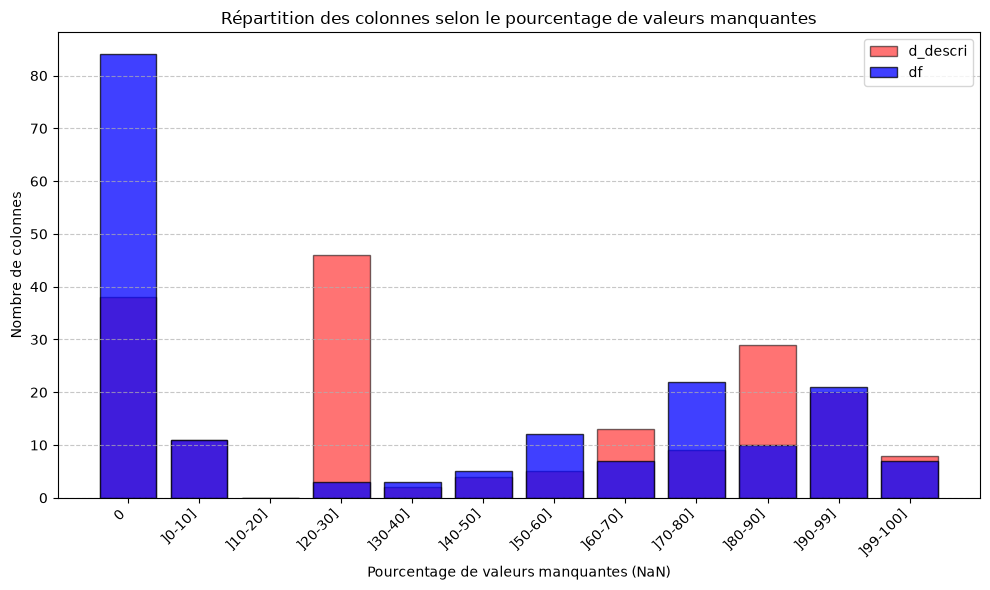

In [13]:
# Pourcentage de valeurs manquantes dans les deux tables
nan_descri = d_descri.isna().mean() * 100
nan_df = df.isna().mean() * 100

bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
labels = [
    '0', ']0-10]', ']10-20]', ']20-30]', ']30-40]', ']40-50]',
    ']50-60]', ']60-70]', ']70-80]', ']80-90]', ']90-99]', ']99-100]'
]

counts_descri = pd.cut(
    nan_descri, bins=bins, labels=labels
).value_counts(sort=False)

counts_df = pd.cut(
    nan_df, bins=bins, labels=labels
).value_counts(sort=False)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))

# Table d_descri en arrière-plan
plt.bar(
    x, counts_descri.values,
    color='red', alpha=0.55,
    edgecolor='black', label='d_descri'
)

# Table df au premier plan
plt.bar(
    x, counts_df.values,
    color='blue', alpha=0.75,
    edgecolor='black', label='df'
)

plt.title("Répartition des colonnes selon le pourcentage de valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes (NaN)")
plt.ylabel("Nombre de colonnes")
plt.xticks(x, labels, rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()

# plt.savefig("graphs/nan_distribution_comparaison.png")
plt.show()